In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/healthcare_preprocessed")

In [3]:
df.head()

,Name,Age,Gender,Blood_Type,Medical_Condition,Admission_Date,Doctor,Hospital,Insurance_Provider,Billing_Amount,Room Number,Admission_Type,Discharge_Date,Medication,Test_Results,Length_of_Stay,Age_Group,Admission_Urgency
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328.0,Urgent,2024-02-02,Paracetamol,Normal,2.0,19-30,Urgent
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265.0,Emergency,2019-08-26,Ibuprofen,Inconclusive,6.0,61-75,Emergency
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205.0,Emergency,2022-10-07,Aspirin,Normal,15.0,76+,Emergency
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450.0,Elective,2020-12-18,Ibuprofen,Abnormal,30.0,19-30,Elective
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458.0,Urgent,2022-10-09,Penicillin,Abnormal,20.0,31-45,Urgent


In [4]:
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Number of rows: 18807
Number of columns: 18


In [5]:
print(df.columns.tolist())

['Name', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition', 'Admission_Date', 'Doctor', 'Hospital', 'Insurance_Provider', 'Billing_Amount', 'Room Number', 'Admission_Type', 'Discharge_Date', 'Medication', 'Test_Results', 'Length_of_Stay', 'Age_Group', 'Admission_Urgency']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18807 entries, 0 to 18806
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                18807 non-null  object 
 1   Age                 18807 non-null  int64  
 2   Gender              18807 non-null  object 
 3   Blood_Type          18807 non-null  object 
 4   Medical_Condition   18807 non-null  object 
 5   Admission_Date      18807 non-null  object 
 6   Doctor              18806 non-null  object 
 7   Hospital            18806 non-null  object 
 8   Insurance_Provider  18806 non-null  object 
 9   Billing_Amount      18806 non-null  float64
 10  Room Number         18806 non-null  float64
 11  Admission_Type      18806 non-null  object 
 12  Discharge_Date      18806 non-null  object 
 13  Medication          18806 non-null  object 
 14  Test_Results        18806 non-null  object 
 15  Length_of_Stay      18806 non-null  float64
 16  Age_

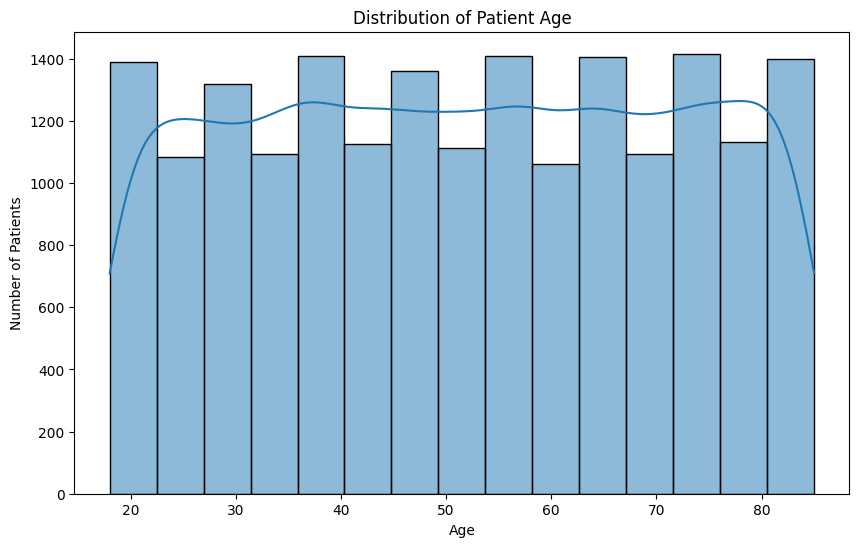

In [7]:
plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)
plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

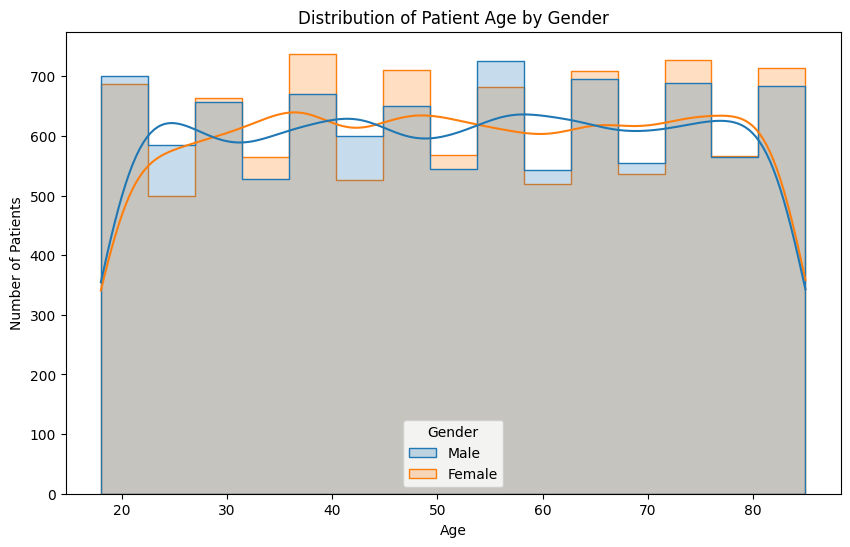

In [8]:
plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="Age",
    hue="Gender",
    bins=15,
    kde=True,
    element="step"
)
plt.title("Distribution of Patient Age by Gender")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

In [9]:
gender_counts = df['Gender'].value_counts()
print(gender_counts)

Gender
Female    9413
Male      9394
Name: count, dtype: int64


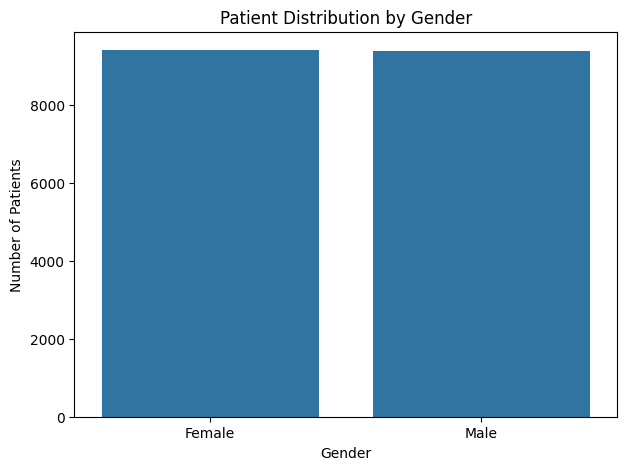

In [10]:
gender_counts=df["Gender"].value_counts()
plt.figure(figsize=(7,5))
sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values)
plt.title("Patient Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()

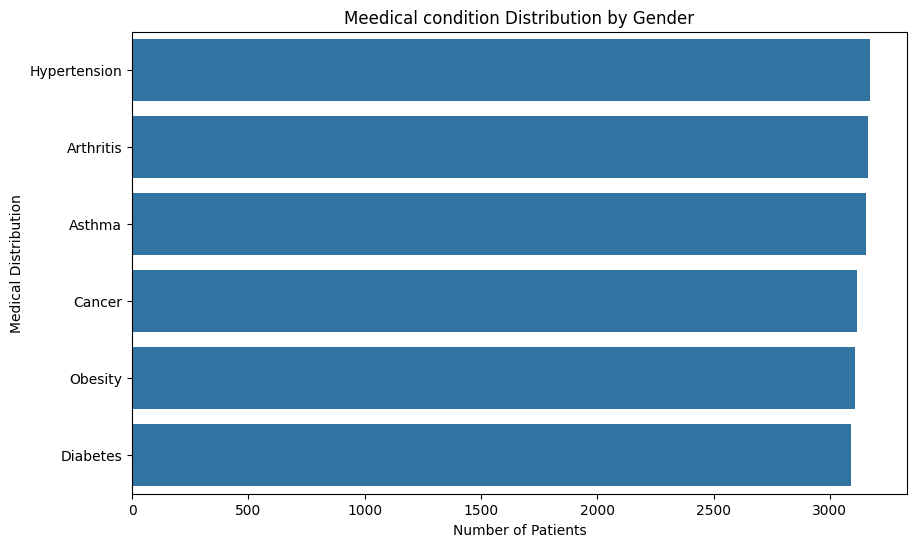

In [11]:
condition_counts=df["Medical_Condition"].value_counts()
plt.figure(figsize=(10,6))
sns.barplot(
    x=condition_counts.values,
    y=condition_counts.index)
plt.title("Meedical condition Distribution by Gender")
plt.xlabel("Number of Patients")
plt.ylabel("Medical Distribution")
plt.show()

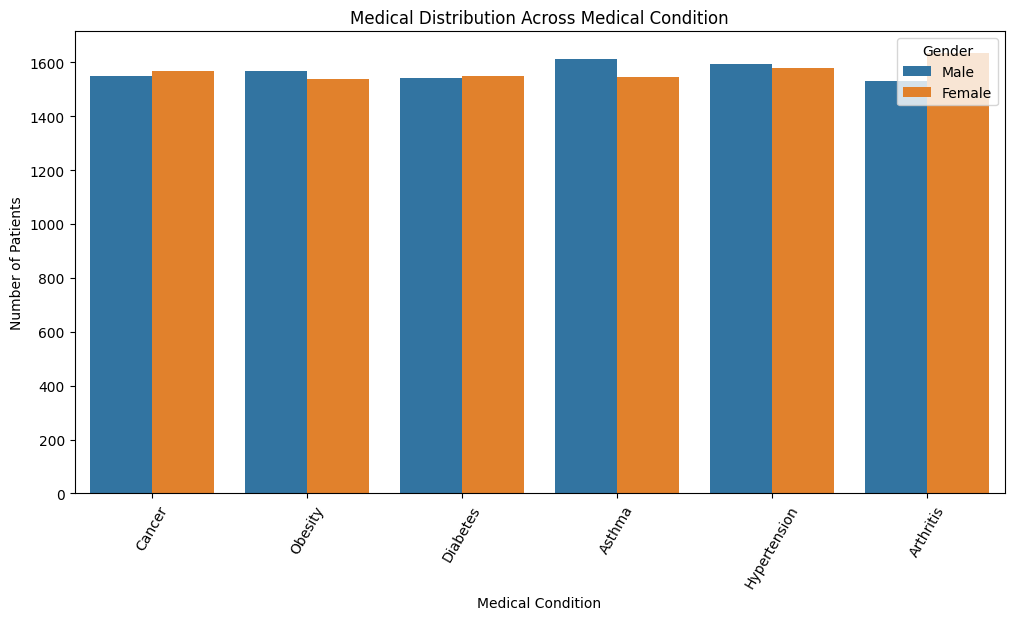

In [12]:
plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x="Medical_Condition",
    hue="Gender"
)
plt.title("Medical Distribution Across Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=60)
plt.show()

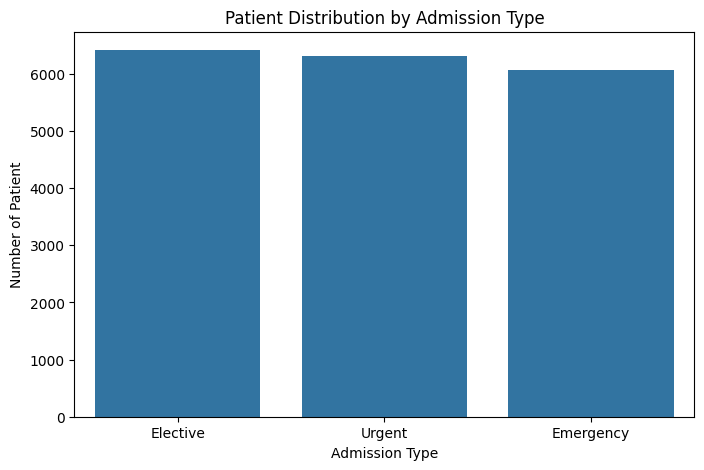

In [13]:
admissions_counts=df["Admission_Type"].value_counts()
plt.figure(figsize=(8,5))
sns.barplot(
    x=admissions_counts.index,
    y=admissions_counts.values)
plt.title("Patient Distribution by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patient")
plt.show()

In [14]:
admissions_condition=pd.crosstab(
    df["Medical_Condition"],
    df["Admission_Type"])
print(admissions_condition)

Admission_Type     Elective  Emergency  Urgent
Medical_Condition                             
Arthritis              1080       1012    1071
Asthma                 1113       1012    1032
Cancer                 1081        991    1045
Diabetes               1032        989    1069
Hypertension           1099       1029    1045
Obesity                1014       1031    1061


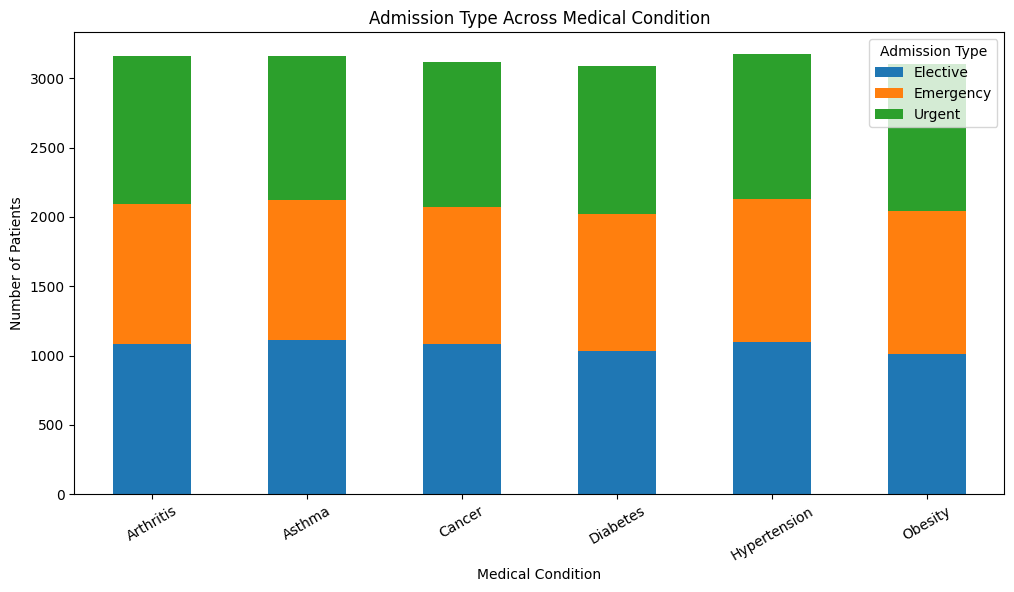

In [15]:
admissions_condition.plot(
    kind="bar",
    stacked=True,
    figsize=(12,6)
)
plt.title("Admission Type Across Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.legend(title="Admission Type")
plt.tight_layout
plt.show()

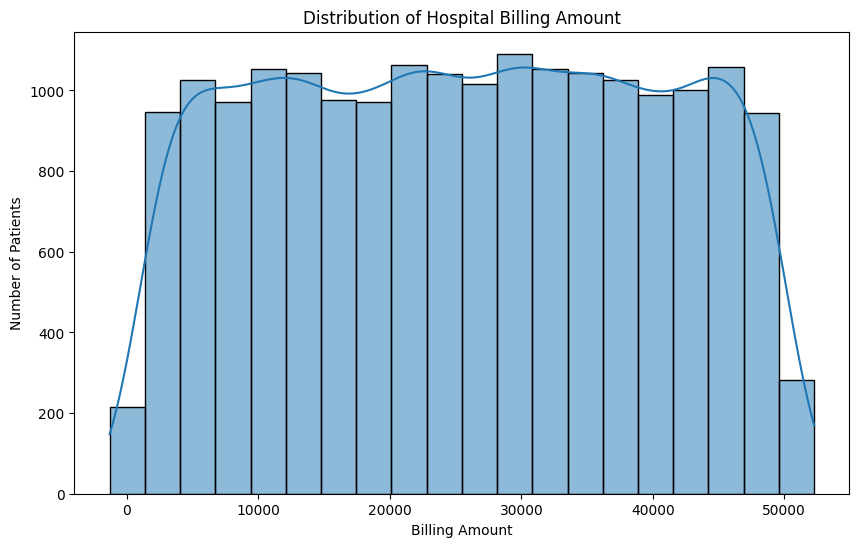

In [16]:
plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="Billing_Amount",
    bins=20,
    kde=True
)
plt.title("Distribution of Hospital Billing Amount")
plt.xlabel("Billing Amount")
plt.ylabel("Number of Patients")
plt.show()


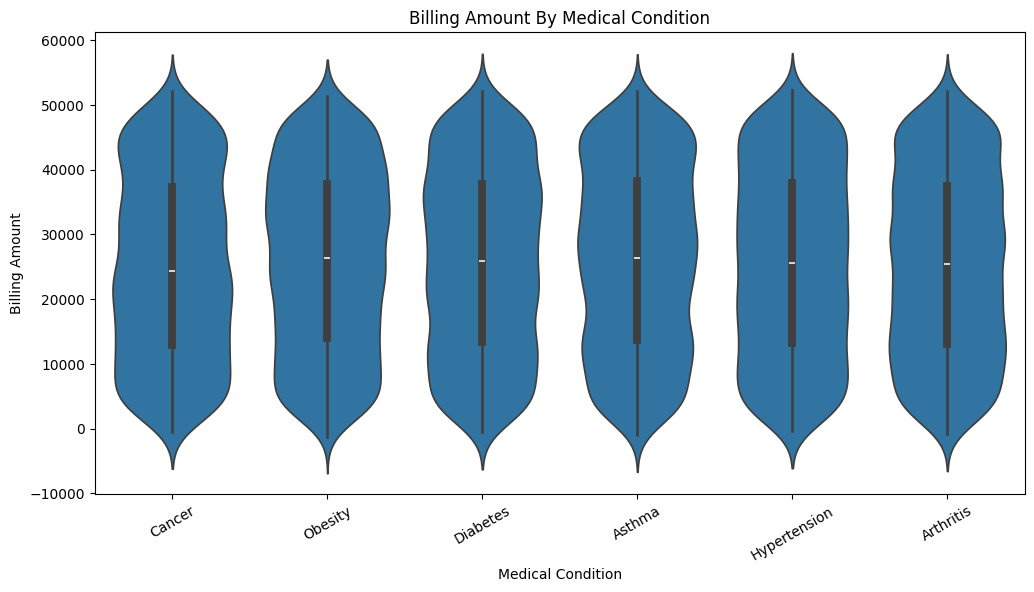

In [17]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df,
    x="Medical_Condition",
    y="Billing_Amount"
)
plt.title("Billing Amount By Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.show()

In [18]:
avg_condition_billing=(
    df.groupby("Medical_Condition")["Billing_Amount"]
    .mean()
    .sort_values(ascending=False)
)
print(avg_condition_billing
)

Medical_Condition
Asthma          26048.980037
Obesity         25921.833709
Diabetes        25757.674816
Hypertension    25591.647555
Arthritis       25407.013328
Cancer          25108.850573
Name: Billing_Amount, dtype: float64


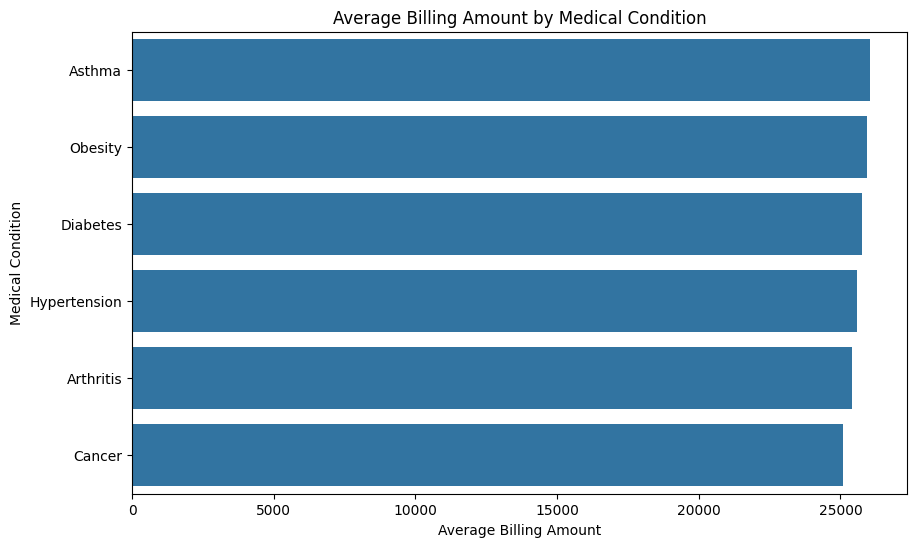

In [19]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=avg_condition_billing.values,
    y=avg_condition_billing.index)
plt.title("Average Billing Amount by Medical Condition")
plt.xlabel("Average Billing Amount")
plt.ylabel("Medical Condition")
plt.show()

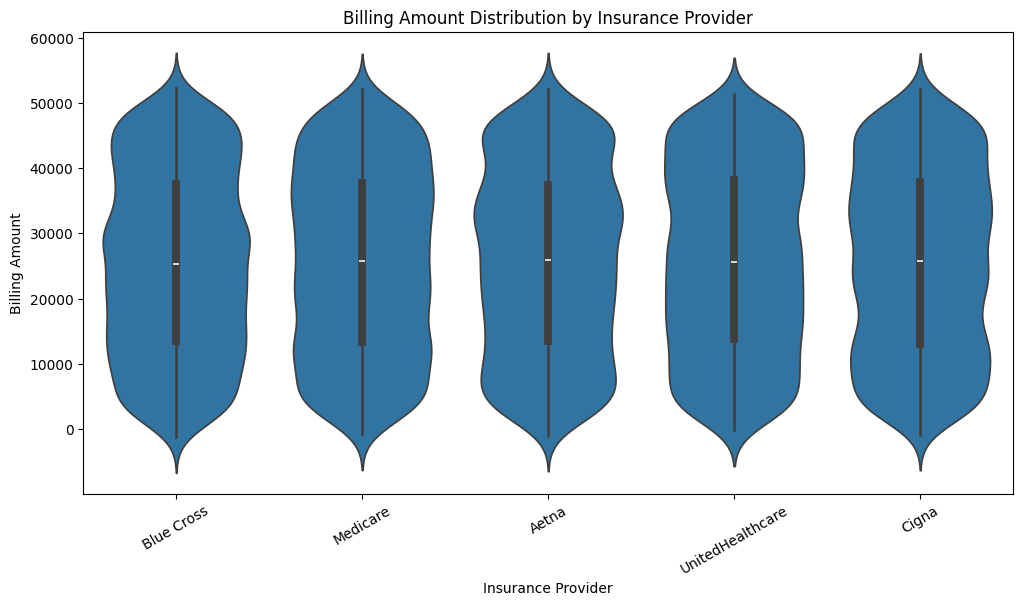

In [20]:
plt.figure(figsize=(12,6))
sns.violinplot(
    data=df,
    x="Insurance_Provider",
    y="Billing_Amount"
)
plt.title("Billing Amount Distribution by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.show()

In [21]:
insurance_billing=(
    df.groupby("Insurance_Provider")["Billing_Amount"]
    .mean()
    .sort_values(ascending=False)
)
print(insurance_billing)

Insurance_Provider
UnitedHealthcare    25786.289561
Aetna               25675.527349
Medicare            25644.700759
Cigna               25598.137288
Blue Cross          25494.081531
Name: Billing_Amount, dtype: float64


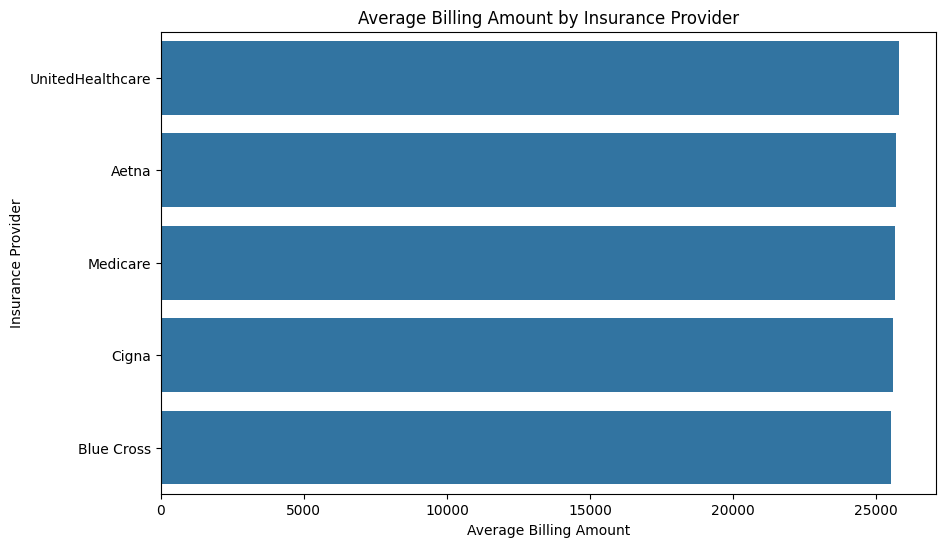

In [22]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=insurance_billing.values,
    y=insurance_billing.index)
plt.title("Average Billing Amount by Insurance Provider")
plt.xlabel("Average Billing Amount")
plt.ylabel("Insurance Provider")
plt.show()

In [23]:
df["Admission_Date"]=pd.to_datetime(df["Admission_Date"])
df["Admission_Month"]=(df["Admission_Date"].dt.to_period("M"))



In [24]:
print(df["Admission_Month"].head())

0    2024-01
1    2019-08
2    2022-09
3    2020-11
4    2022-09
Name: Admission_Month, dtype: period[M]


In [26]:
monthly_admissions=(df.groupby("Admission_Month").size().reset_index(name="Admission"))


In [27]:
monthly_admissions["Admission_Month"]=monthly_admissions["Admission_Month"].dt.to_timestamp()

In [28]:
print(monthly_admissions)

   Admission_Month  Admission
0       2019-05-01        236
1       2019-06-01        314
2       2019-07-01        297
3       2019-08-01        336
4       2019-09-01        306
..             ...        ...
56      2024-01-01        308
57      2024-02-01        282
58      2024-03-01        327
59      2024-04-01        312
60      2024-05-01         77

[61 rows x 2 columns]


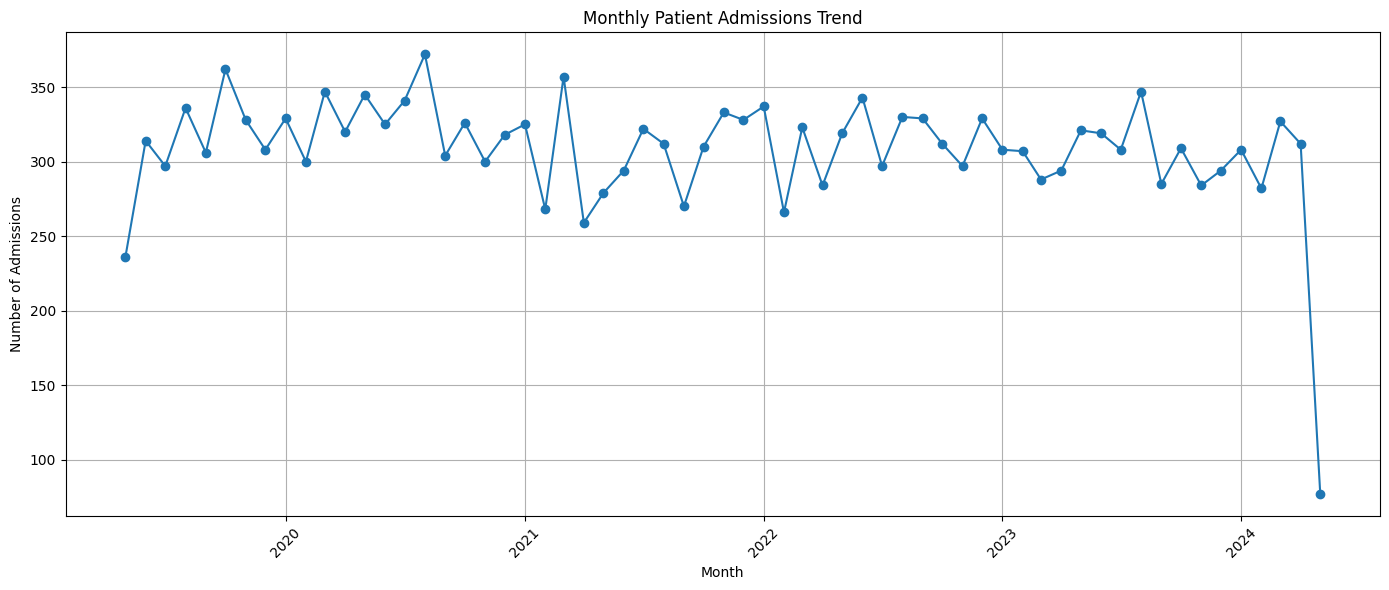

In [30]:
plt.figure(figsize=(14,6))
plt.plot(
    monthly_admissions["Admission_Month"],
    monthly_admissions["Admission"],
    marker="o"
)
plt.title("Monthly Patient Admissions Trend")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [31]:
correlation_data=df[
    [
        "Age",
        "Length_of_Stay",
        "Billing_Amount"
    ]
]

In [32]:
corrolation_matrix=correlation_data.corr()
print(corrolation_matrix)

                     Age  Length_of_Stay  Billing_Amount
Age             1.000000        0.007563        0.001849
Length_of_Stay  0.007563        1.000000        0.000531
Billing_Amount  0.001849        0.000531        1.000000
